# Simplex experiments
Abby Nguyen · CSE 620 Project 2. This part covers n=30,40,50


## 1 Setup


In [1]:
import statistics
import time

import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

VARIABLE_COUNTS = (30, 40, 50)
CONSTRAINT_COUNTS = (2, 6, 10, 14)
RANDOM_SEEDS = (620, 621, 622, 623, 624)
TIMING_REPEATS = 11
TOLERANCE = 1e-9


In [2]:
def display_table(records, columns):
    # Build a readable table directly in the notebook output.
    column_labels = []
    for field_name, label in columns:
        column_labels.append(label)

    table_lines = [' | '.join(column_labels)]
    table_lines.append(' | '.join(['---'] * len(columns)))

    for record in records:
        row_values = []
        for field_name, label in columns:
            value = record[field_name]
            if isinstance(value, (float, np.floating)):
                value = f'{value:.6g}'  # Display precision; stored values stay unchanged.
            row_values.append(str(value))
        table_lines.append(' | '.join(row_values))

    display(Markdown('\n'.join(table_lines)))


In [3]:
combination_count = len(VARIABLE_COUNTS) * len(CONSTRAINT_COUNTS)
case_count = combination_count * len(RANDOM_SEEDS)
timing_count = case_count * TIMING_REPEATS

print('EXPERIMENT SETTINGS')
print('Variable counts:', VARIABLE_COUNTS)
print('Constraint counts:', CONSTRAINT_COUNTS)
print('Seeds:', RANDOM_SEEDS)
print('Size combinations:', combination_count)
print('Seeded cases:', case_count)
print('Timed solves:', timing_count)


EXPERIMENT SETTINGS
Variable counts: (30, 40, 50)
Constraint counts: (2, 6, 10, 14)
Seeds: (620, 621, 622, 623, 624)
Size combinations: 12
Seeded cases: 60
Timed solves: 660


## 2 Two-phase Simplex


### Prepare constraint rows


In [4]:
def prepare_constraint_rows(c, A_eq, b_eq, A_ub, b_ub):
    # Standard LP names: c is the cost vector; eq means equality; ub means upper bound.
    objective_coefficients = np.asarray(c, dtype=float)
    if objective_coefficients.ndim != 1:
        raise ValueError('Objective coefficients must be a one-dimensional vector')
    if not np.isfinite(objective_coefficients).all():
        raise ValueError('Objective coefficients must be finite')

    variable_count = len(objective_coefficients)
    constraint_rows = []
    right_hand_sides = []
    constraint_types = []
    constraint_groups = [(A_eq, b_eq, '='), (A_ub, b_ub, '<=')]

    for matrix, bounds, constraint_type in constraint_groups:
        if matrix is None:
            if bounds is not None:
                raise ValueError('Constraint bounds require a matrix')
            continue

        matrix = np.asarray(matrix, dtype=float)
        bounds = np.asarray(bounds, dtype=float)
        if bounds.ndim != 1 or matrix.shape != (bounds.size, variable_count):
            raise ValueError('Constraint dimensions do not match')
        if not np.isfinite(matrix).all() or not np.isfinite(bounds).all():
            raise ValueError('Constraint values must be finite')

        for coefficients, bound in zip(matrix, bounds):
            row_type = constraint_type
            # Make the right-hand side nonnegative before building a basis.
            if bound < 0:
                coefficients = -coefficients
                bound = -bound
                if row_type == '<=':
                    row_type = '>='
            constraint_rows.append(coefficients)
            right_hand_sides.append(bound)
            constraint_types.append(row_type)

    return objective_coefficients, constraint_rows, right_hand_sides, constraint_types


### Build the starting tableau


In [5]:
def build_starting_tableau(constraint_rows, right_hand_sides, constraint_types,
                           variable_count, initial_basis, tolerance):
    row_count = len(constraint_rows)
    extra_column_count = 0
    rows_needing_artificial_variables = []

    for row_index, constraint_type in enumerate(constraint_types):
        if constraint_type != '=':
            extra_column_count += 1
        if constraint_type != '<=':
            rows_needing_artificial_variables.append(row_index)

    # Columns hold original variables, slack/surplus variables, then artificial variables.
    ordinary_column_count = variable_count + extra_column_count
    tableau_column_count = ordinary_column_count
    if initial_basis is None:
        tableau_column_count += len(rows_needing_artificial_variables)

    tableau = np.zeros((row_count, tableau_column_count + 1))
    if row_count > 0:
        tableau[:, :variable_count] = constraint_rows
        tableau[:, -1] = right_hand_sides

    # A <= row gets a slack variable; a >= row gets a surplus variable.
    basis = [-1] * row_count
    next_column = variable_count
    for row_index, constraint_type in enumerate(constraint_types):
        if constraint_type == '<=':
            tableau[row_index, next_column] = 1
            basis[row_index] = next_column
            next_column += 1
        elif constraint_type == '>=':
            tableau[row_index, next_column] = -1
            next_column += 1

    artificial_columns = []
    # Use artificial variables when a feasible starting basis was not supplied.
    if initial_basis is None:
        for row_index in rows_needing_artificial_variables:
            tableau[row_index, next_column] = 1
            basis[row_index] = next_column
            artificial_columns.append(next_column)
            next_column += 1
    else:
        basis = list(initial_basis)
        if len(basis) != row_count or len(set(basis)) != row_count:
            raise ValueError('The initial basis must contain one distinct column per row')
        for column_index in basis:
            if column_index < 0 or column_index >= ordinary_column_count:
                raise ValueError('Initial basis column is out of range')
        # Convert the supplied basis into identity columns in the tableau.
        basis_matrix = tableau[:, basis]
        tableau = np.linalg.solve(basis_matrix, tableau)
        if np.any(tableau[:, -1] < -tolerance):
            raise ValueError('The initial basis is infeasible')

    return tableau, basis, artificial_columns, ordinary_column_count


### Apply one pivot


In [6]:
def apply_pivot(tableau, basis, leaving_row, entering_column,
                pivot_counts, phase_name, tolerance):
    pivot_value = tableau[leaving_row, entering_column]
    step_length = tableau[leaving_row, -1] / pivot_value
    if abs(step_length) <= tolerance:
        pivot_counts['degenerate_pivots'] += 1

    # Normalize the pivot row, then eliminate this column from the other rows.
    tableau[leaving_row] /= pivot_value
    for row_index in range(len(basis)):
        if row_index == leaving_row:
            continue
        elimination_factor = tableau[row_index, entering_column]
        tableau[row_index] -= elimination_factor * tableau[leaving_row]

    tableau[:, entering_column] = 0
    tableau[leaving_row, entering_column] = 1
    # One basis exchange counts as one pivot, including zero-step exchanges.
    basis[leaving_row] = entering_column
    pivot_counts[phase_name] += 1


def total_pivots(pivot_counts):
    return (
        pivot_counts['phase1_pivots']
        + pivot_counts['cleanup_pivots']
        + pivot_counts['phase2_pivots']
    )


### Choose the entering column and leaving row


In [7]:
def choose_entering_column(reduced_costs, tolerance):
    # Bland's rule: choose the smallest column index with a negative reduced cost.
    for column_index, reduced_cost in enumerate(reduced_costs):
        if reduced_cost < -tolerance:
            return column_index
    return None


def choose_leaving_row(tableau, basis, entering_column, tolerance):
    eligible_rows = []
    step_lengths = []

    for row_index in range(len(basis)):
        coefficient = tableau[row_index, entering_column]
        if coefficient > tolerance:
            right_hand_side = max(tableau[row_index, -1], 0)
            step_length = right_hand_side / coefficient
            eligible_rows.append(row_index)
            step_lengths.append(step_length)

    if not eligible_rows:
        return None

    # The smallest ratio keeps the next solution feasible.
    minimum_step = min(step_lengths)
    leaving_row = None
    for row_index, step_length in zip(eligible_rows, step_lengths):
        # Break ratio ties using the smallest basic-variable index.
        if abs(step_length - minimum_step) <= tolerance:
            if leaving_row is None or basis[row_index] < basis[leaving_row]:
                leaving_row = row_index

    return leaving_row


### Optimize one phase


In [8]:
def optimize_phase(tableau, basis, costs, pivot_counts, phase_name,
                   tolerance, max_pivots):
    while True:
        basic_costs = costs[basis]
        constraint_coefficients = tableau[:, :-1]
        # Reduced cost = original column cost minus the cost implied by the current basis.
        reduced_costs = costs - basic_costs @ constraint_coefficients
        reduced_costs[basis] = 0

        entering_column = choose_entering_column(reduced_costs, tolerance)
        if entering_column is None:
            return 'optimal'  # No improving column remains.
        if total_pivots(pivot_counts) >= max_pivots:
            return 'iteration_limit'

        leaving_row = choose_leaving_row(tableau, basis, entering_column, tolerance)
        if leaving_row is None:
            return 'unbounded'  # No row limits movement along the entering column.

        apply_pivot(
            tableau, basis, leaving_row, entering_column,
            pivot_counts, phase_name, tolerance,
        )


### Remove artificial variables and build the answer


In [9]:
def remove_artificial_variables(tableau, basis, artificial_columns,
                                 ordinary_column_count, pivot_counts, tolerance):
    for row_index in range(len(basis) - 1, -1, -1):
        if basis[row_index] not in artificial_columns:
            continue

        # A zero artificial basic variable must leave the basis.
        replacement_column = None
        for column_index in range(ordinary_column_count):
            if column_index in basis:
                continue
            if abs(tableau[row_index, column_index]) > tolerance:
                replacement_column = column_index
                break

        # If no original/slack column can replace it, the row is redundant.
        if replacement_column is None:
            tableau = np.delete(tableau, row_index, axis=0)
            basis.pop(row_index)
            pivot_counts['removed_redundant_rows'] += 1
        else:
            apply_pivot(
                tableau, basis, row_index, replacement_column,
                pivot_counts, 'cleanup_pivots', tolerance,
            )

    tableau = np.delete(tableau, artificial_columns, axis=1)
    return tableau


def build_solution(status, tableau, basis, objective_coefficients,
                   pivot_counts, tolerance):
    solution = pivot_counts.copy()
    solution['status'] = status
    solution['pivots'] = total_pivots(pivot_counts)
    solution['basis'] = basis.copy()
    solution['x'] = None
    solution['objective'] = None

    if status == 'optimal':
        all_variable_values = np.zeros(tableau.shape[1] - 1)
        all_variable_values[basis] = tableau[:, -1]
        variable_count = len(objective_coefficients)
        # Return only the original decision variables, excluding added tableau columns.
        original_variables = all_variable_values[:variable_count]
        original_variables[np.abs(original_variables) < tolerance] = 0
        solution['x'] = original_variables.tolist()
        solution['objective'] = float(objective_coefficients @ original_variables)

    return solution


### Run Phase I and Phase II


In [10]:
def simplex(c, A_eq=None, b_eq=None, A_ub=None, b_ub=None,
            initial_basis=None, tolerance=TOLERANCE, max_pivots=10000):
    objective_coefficients, rows, bounds, row_types = prepare_constraint_rows(
        c, A_eq, b_eq, A_ub, b_ub,
    )
    variable_count = len(objective_coefficients)
    tableau, basis, artificial_columns, ordinary_column_count = build_starting_tableau(
        rows, bounds, row_types, variable_count, initial_basis, tolerance,
    )
    pivot_counts = {
        'phase1_pivots': 0,
        'cleanup_pivots': 0,
        'phase2_pivots': 0,
        'degenerate_pivots': 0,
        'removed_redundant_rows': 0,
    }

    # Phase I minimizes the sum of artificial variables to find a feasible basis.
    if artificial_columns:
        phase1_costs = np.zeros(tableau.shape[1] - 1)
        phase1_costs[artificial_columns] = 1
        status = optimize_phase(
            tableau, basis, phase1_costs, pivot_counts,
            'phase1_pivots', tolerance, max_pivots,
        )
        if status == 'optimal':
            artificial_variable_total = phase1_costs[basis] @ tableau[:, -1]
            # A positive Phase I minimum means the original constraints are infeasible.
            if artificial_variable_total > tolerance:
                status = 'infeasible'
        if status != 'optimal':
            return build_solution(
                status, tableau, basis, objective_coefficients, pivot_counts, tolerance,
            )
        tableau = remove_artificial_variables(
            tableau, basis, artificial_columns, ordinary_column_count,
            pivot_counts, tolerance,
        )

    # Phase II uses the original objective after artificial variables are removed.
    phase2_costs = np.zeros(tableau.shape[1] - 1)
    phase2_costs[:variable_count] = objective_coefficients
    status = optimize_phase(
        tableau, basis, phase2_costs, pivot_counts,
        'phase2_pivots', tolerance, max_pivots,
    )
    return build_solution(
        status, tableau, basis, objective_coefficients, pivot_counts, tolerance,
    )


### Check answers independently


In [11]:
def validate(problem, solution):
    # HiGHS checks the answer outside the measured solve time.
    reference = linprog(**problem, bounds=(0, None), method='highs-ds')
    expected_statuses = {0: 'optimal', 2: 'infeasible', 3: 'unbounded'}
    expected_status = expected_statuses.get(reference.status)
    assert solution['status'] == expected_status, reference.message

    maximum_violation = 0.0
    reference_objective = None
    if solution['status'] == 'optimal':
        reference_objective = float(reference.fun)
        assert np.isclose(solution['objective'], reference_objective, rtol=1e-7, atol=1e-7)

        # Check nonnegativity and every original constraint.
        variable_values = np.asarray(solution['x'])
        maximum_violation = max(0.0, float(-variable_values.min()))

        if 'A_eq' in problem:
            equality_matrix = np.asarray(problem['A_eq'])
            equality_bounds = np.asarray(problem['b_eq'])
            if equality_matrix.size > 0:
                equality_errors = equality_matrix @ variable_values - equality_bounds
                equality_violation = float(np.max(np.abs(equality_errors)))
                maximum_violation = max(maximum_violation, equality_violation)

        if 'A_ub' in problem:
            inequality_matrix = np.asarray(problem['A_ub'])
            inequality_bounds = np.asarray(problem['b_ub'])
            if inequality_matrix.size > 0:
                inequality_errors = inequality_matrix @ variable_values - inequality_bounds
                inequality_violation = float(np.max(np.maximum(inequality_errors, 0)))
                maximum_violation = max(maximum_violation, inequality_violation)

        assert maximum_violation < 1e-7, maximum_violation

    return {
        'highs_status': int(reference.status),
        'highs_objective': reference_objective,
        'max_violation': maximum_violation,
        'validated': True,
    }


## 3 Lecture example
\[
\min 7x_1+4x_2+6x_3+x_4
\]
\[
x_1+2x_2-x_3-x_4=1,\quad -x_1-5x_2+2x_3+3x_4=1,\quad x\geq0.
\]


In [12]:
def lecture_problem():
    return {
        'c': np.array([7.0, 4.0, 6.0, 1.0]),
        'A_eq': np.array([
            [1.0, 2.0, -1.0, -1.0],
            [-1.0, -5.0, 2.0, 3.0],
        ]),
        'b_eq': np.array([1.0, 1.0]),
    }


lecture = lecture_problem()
# Python indices [0, 2] represent the lecture basis {x1, x3}.
supplied_basis_solution = simplex(**lecture, initial_basis=[0, 2])
automatic_basis_solution = simplex(**lecture)
validate(lecture, supplied_basis_solution)
validate(lecture, automatic_basis_solution)

assert supplied_basis_solution['pivots'] == 1
assert np.allclose(supplied_basis_solution['x'], [2, 0, 0, 1])

lecture_results = []
for label, solution in [
    ('Supplied basis', supplied_basis_solution),
    ('Automatic initialization', automatic_basis_solution),
]:
    result = solution.copy()
    result['start'] = label
    lecture_results.append(result)

display_table(lecture_results, [
    ('start', 'Start'),
    ('objective', 'Minimum'),
    ('x', 'Solution x'),
    ('phase1_pivots', 'Phase I'),
    ('cleanup_pivots', 'Cleanup'),
    ('phase2_pivots', 'Phase II'),
    ('pivots', 'Total pivots'),
])


Start | Minimum | Solution x | Phase I | Cleanup | Phase II | Total pivots
--- | --- | --- | --- | --- | --- | ---
Supplied basis | 15 | [2.0, 0.0, 0.0, 1.0] | 0 | 0 | 1 | 1
Automatic initialization | 15 | [2.0, 0.0, 0.0, 1.0] | 2 | 0 | 1 | 3

## 4 Generate the experiments


In [13]:
def generate_family(seed):
    random_generator = np.random.default_rng(seed)

    # Generate the same full family as the report, then take smaller prefixes.
    objective_coefficients = random_generator.integers(1, 10, size=50).astype(float)
    objective_coefficients[:4] = [7, 4, 6, 1]

    equality_matrix = random_generator.integers(-5, 6, size=(50, 2)).T.astype(float)
    equality_matrix[:, :4] = lecture_problem()['A_eq']

    inequality_matrix = random_generator.integers(-5, 6, size=(12, 50)).astype(float)
    # This witness keeps every selected size feasible. Positive costs bound the minimum.
    feasible_witness = np.zeros(50)
    feasible_witness[0] = 2
    feasible_witness[3] = 1
    extra_capacity = random_generator.integers(1, 9, size=12)
    inequality_bounds = inequality_matrix @ feasible_witness + extra_capacity

    return {
        'c': objective_coefficients,
        'A_eq': equality_matrix,
        'A_ub': inequality_matrix,
        'b_ub': inequality_bounds,
    }


def select_problem_size(family, variable_count, constraint_count):
    # Every model retains two equality rows; the remaining rows are inequalities.
    inequality_count = constraint_count - 2
    return {
        'c': family['c'][:variable_count],
        'A_eq': family['A_eq'][:, :variable_count],
        'b_eq': np.ones(2),
        'A_ub': family['A_ub'][:inequality_count, :variable_count],
        'b_ub': family['b_ub'][:inequality_count],
    }


In [14]:
experiments = []

# Adding columns preserves old choices; adding rows restricts the feasible set.
for seed in RANDOM_SEEDS:
    family = generate_family(seed)
    for variable_count in VARIABLE_COUNTS:
        for constraint_count in CONSTRAINT_COUNTS:
            problem = select_problem_size(family, variable_count, constraint_count)
            experiment = {
                'seed': seed,
                'n': variable_count,
                'm': constraint_count,
                'problem': problem,
            }
            experiments.append(experiment)

print('Created', len(experiments), 'experiments.')
print('Each experiment retains the two lecture equality rows.')


Created 60 experiments.
Each experiment retains the two lecture equality rows.


## 5 Run the experiments


In [15]:
def measure_experiment(experiment, repeat_count):
    problem = experiment['problem']
    # Warmup and independent validation are outside the timed region.
    warmup_solution = simplex(**problem)
    verification = validate(problem, warmup_solution)
    elapsed_times = []
    timing_records = []

    for repeat_number in range(1, repeat_count + 1):
        # Time only the complete Simplex solve, including both phases and cleanup.
        start_time = time.perf_counter_ns()
        solution = simplex(**problem)
        end_time = time.perf_counter_ns()
        elapsed_ms = (end_time - start_time) / 1e6

        assert solution['status'] == warmup_solution['status']
        assert solution['pivots'] == warmup_solution['pivots']
        elapsed_times.append(elapsed_ms)
        timing_records.append({
            'seed': experiment['seed'],
            'n': experiment['n'],
            'm': experiment['m'],
            'repeat': repeat_number,
            'time_ms': elapsed_ms,
            'pivots': solution['pivots'],
        })

    nonzero_count = 0
    for value in warmup_solution['x']:
        if abs(value) > 1e-8:
            nonzero_count += 1

    record = {
        'seed': experiment['seed'],
        'n': experiment['n'],
        'm': experiment['m'],
        'status': warmup_solution['status'],
        'objective': warmup_solution['objective'],
        'median_ms': statistics.median(elapsed_times),
        'min_ms': min(elapsed_times),
        'max_ms': max(elapsed_times),
        'nonzero_variables': nonzero_count,
        'zero_percent': 100 * (experiment['n'] - nonzero_count) / experiment['n'],
        'x': warmup_solution['x'].copy(),
    }
    for field_name in ['pivots', 'phase1_pivots', 'cleanup_pivots',
                       'phase2_pivots', 'degenerate_pivots']:
        record[field_name] = warmup_solution[field_name]
    record.update(verification)
    return record, timing_records


In [16]:
case_results = []
raw_timings = []
# Shuffle case order to reduce systematic warming and execution-order effects.
random_order = np.random.default_rng(20261017).permutation(len(experiments))

for experiment_index in random_order:
    experiment = experiments[experiment_index]
    case_record, timing_records = measure_experiment(experiment, TIMING_REPEATS)
    case_results.append(case_record)
    raw_timings.extend(timing_records)


def experiment_order(record):
    return record['n'], record['m'], record['seed']


case_results.sort(key=experiment_order)
largest_violation = 0.0
for record in case_results:
    largest_violation = max(largest_violation, record['max_violation'])

assert len(case_results) == case_count
assert len(raw_timings) == timing_count
print(len(case_results), 'cases and', len(raw_timings), 'timings completed.')
print('All cases independently validated.')
print('Largest constraint violation:', largest_violation)


60 cases and 660 timings completed.
All cases independently validated.
Largest constraint violation: 1.865174681370263e-14


### Summary by problem size


In [17]:
def summarize_cases(case_results):
    # Summarize five seeds per size; each case time is a median of eleven repeats.
    summary = []
    for variable_count in VARIABLE_COUNTS:
        for constraint_count in CONSTRAINT_COUNTS:
            case_medians = []
            pivot_counts = []
            objectives = []
            nonzero_counts = []
            zero_percentages = []

            for record in case_results:
                if record['n'] != variable_count or record['m'] != constraint_count:
                    continue
                case_medians.append(record['median_ms'])
                pivot_counts.append(record['pivots'])
                objectives.append(record['objective'])
                nonzero_counts.append(record['nonzero_variables'])
                zero_percentages.append(record['zero_percent'])

            summary.append({
                'n': variable_count,
                'm': constraint_count,
                'cases': len(case_medians),
                'median_ms': statistics.median(case_medians),
                'mean_pivots': statistics.mean(pivot_counts),
                'min_pivots': min(pivot_counts),
                'max_pivots': max(pivot_counts),
                'mean_objective': statistics.mean(objectives),
                'mean_nonzeros': statistics.mean(nonzero_counts),
                'mean_zero_percent': statistics.mean(zero_percentages),
            })
    return summary


summary_results = summarize_cases(case_results)
summary_columns = [
    ('n', 'Variables n'),
    ('m', 'Rows m'),
    ('median_ms', 'Median ms'),
    ('mean_pivots', 'Mean pivots'),
    ('mean_objective', 'Mean objective'),
    ('mean_nonzeros', 'Mean nonzeros'),
    ('mean_zero_percent', 'Mean zeros %'),
]
display_table(summary_results, summary_columns)


Variables n | Rows m | Median ms | Mean pivots | Mean objective | Mean nonzeros | Mean zeros %
--- | --- | --- | --- | --- | --- | ---
30 | 2 | 0.21431 | 8.6 | 0.596301 | 1.8 | 94
30 | 6 | 1.13121 | 20.6 | 1.80268 | 3 | 90
30 | 10 | 1.23379 | 17.8 | 4.6253 | 4 | 86.6667
30 | 14 | 2.01909 | 30.4 | 6.94743 | 5.8 | 80.6667
40 | 2 | 0.28936 | 9 | 0.511444 | 1.8 | 95.5
40 | 6 | 1.5752 | 23.6 | 1.62606 | 3 | 92.5
40 | 10 | 1.22981 | 20.4 | 4.04127 | 4 | 90
40 | 14 | 3.05512 | 40.2 | 6.41967 | 6 | 85
50 | 2 | 0.4567 | 9.4 | 0.492991 | 1.8 | 96.4
50 | 6 | 1.42278 | 27.8 | 1.47073 | 3.2 | 93.6
50 | 10 | 0.82203 | 21.6 | 3.79537 | 4.2 | 91.6
50 | 14 | 2.46396 | 45.2 | 6.29157 | 6.4 | 87.2

### Individual solutions


In [18]:
# Display every solution with short numeric labels; the full values stay in memory.
for variable_count in VARIABLE_COUNTS:
    display_rows = []
    for result in case_results:
        if result['n'] != variable_count:
            continue

        coordinates = []
        for value in result['x']:
            coordinates.append(f'{value:.4g}')

        display_rows.append({
            'seed': result['seed'],
            'm': result['m'],
            'objective': result['objective'],
            'pivots': result['pivots'],
            'median_ms': result['median_ms'],
            'x': '[' + ', '.join(coordinates) + ']',
        })

    print(f'VARIABLES n = {variable_count} — solution coordinates shown to 4 significant digits')
    display_table(display_rows, [
        ('seed', 'Seed'),
        ('m', 'Rows m'),
        ('objective', 'Minimum'),
        ('pivots', 'Pivots'),
        ('median_ms', 'Median ms'),
        ('x', 'Solution x'),
    ])


VARIABLES n = 30 — solution coordinates shown to 4 significant digits


Seed | Rows m | Minimum | Pivots | Median ms | Solution x
--- | --- | --- | --- | --- | ---
620 | 2 | 0.5 | 8 | 0.1975 | [0, 0, 0, 0, 0, 0, 0, 0, 0.2143, 0, 0, 0, 0, 0, 0, 0.03571, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 2 | 0.818182 | 5 | 0.179429 | [0, 0, 0, 0.4545, 0, 0, 0, 0, 0, 0, 0, 0, 0.3636, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
622 | 2 | 0.666667 | 9 | 0.21431 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3333, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
623 | 2 | 0.692308 | 12 | 0.26727 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.07692, 0, 0, 0, 0, 0, 0, 0, 0, 0.3077]
624 | 2 | 0.304348 | 9 | 0.47175 | [0, 0, 0, 0, 0, 0.1304, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1739, 0, 0]
620 | 6 | 0.5 | 21 | 1.13121 | [0, 0, 0, 0, 0, 0, 0, 0, 0.2143, 0, 0, 0, 0, 0, 0, 0.03571, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 6 | 1.78571 | 20 | 1.23004 | [0, 0, 0, 0.8143, 0, 0, 0, 0, 0, 0.5429, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.07143, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
622 | 6 | 2.6725 | 18 | 0.55647 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.0775, 0.2425, 0, 0.575, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.32, 0]
623 | 6 | 0.964286 | 24 | 1.32545 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1071, 0, 0, 0, 0, 0, 0.3929, 0, 0, 0.03571]
624 | 6 | 3.09091 | 20 | 0.627209 | [0, 0, 0, 0, 0, 0.6364, 0, 0, 0.2727, 0.3636, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
620 | 10 | 3.56549 | 18 | 1.3402 | [0, 0, 0, 0.9445, 0, 0, 0, 0.0678, 0, 0, 0, 0.3529, 0, 0, 0, 0.7473, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 10 | 1.78571 | 28 | 2.38564 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0.4524, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.07143, 0, 0, 0, 0.4524, 0, 0, 0, 0, 0, 0]
622 | 10 | 2.83122 | 14 | 0.6013 | [0, 0.1628, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3257, 0.1896, 0, 0.4529, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.02698, 0]
623 | 10 | 9.90062 | 16 | 0.67594 | [0.1429, 0, 0.528, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.6273, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.298]
624 | 10 | 5.04348 | 13 | 1.23379 | [0, 0.4348, 0, 0, 0, 0.6848, 0.5543, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.4022]
620 | 14 | 7.30235 | 41 | 2.01909 | [0.7379, 0, 0, 0.8945, 0, 0.01255, 0, 0.03794, 0, 0, 0.07886, 0.08557, 0, 0, 0, 0.2848, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 14 | 4.60395 | 47 | 4.7128 | [0, 0, 0, 1.739, 0, 0, 0.1318, 0, 0, 0.4905, 0, 0, 0.26, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.8598, 0, 0, 0, 0]
622 | 14 | 6.83933 | 19 | 2.35486 | [0.4677, 0.2225, 0, 0.7853, 0, 0, 0, 0, 0, 0, 0, 0, 0.09702, 0, 0.08434, 0, 0, 0.1955, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.4228, 0]
623 | 14 | 9.90062 | 22 | 1.11843 | [0.1429, 0, 0.528, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.6273, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.298]
624 | 14 | 6.09092 | 23 | 1.15414 | [0.0642, 0.2737, 0, 0, 0, 1.492, 0, 0, 0.2514, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.5274, 0, 0, 0, 0.6933]

VARIABLES n = 40 — solution coordinates shown to 4 significant digits


Seed | Rows m | Minimum | Pivots | Median ms | Solution x
--- | --- | --- | --- | --- | ---
620 | 2 | 0.5 | 8 | 0.47362 | [0, 0, 0, 0, 0, 0, 0, 0, 0.2143, 0, 0, 0, 0, 0, 0, 0.03571, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 2 | 0.5 | 6 | 0.2585 | [0, 0, 0, 0.25, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.25, 0, 0, 0, 0, 0, 0, 0, 0]
622 | 2 | 0.666667 | 9 | 0.22439 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3333, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
623 | 2 | 0.586207 | 13 | 0.28936 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3103, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1379, 0, 0, 0]
624 | 2 | 0.304348 | 9 | 0.50657 | [0, 0, 0, 0, 0, 0.1304, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1739, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
620 | 6 | 0.5 | 24 | 1.5752 | [0, 0, 0, 0, 0, 0, 0, 0, 0.2143, 0, 0, 0, 0, 0, 0, 0.03571, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 6 | 1.78571 | 27 | 1.71417 | [0, 0, 0, 0.8143, 0, 0, 0, 0, 0, 0.5429, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.07143, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
622 | 6 | 2.08142 | 19 | 0.61178 | [0, 0.00885, 0, 0, 0.2212, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1504, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.508, 0, 0, 0, 0, 0, 0, 0, 0]
623 | 6 | 0.96319 | 25 | 1.59163 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1288, 0, 0, 0, 0, 0, 0.4049, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.01227, 0, 0, 0]
624 | 6 | 2.8 | 23 | 0.68336 | [0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.8, 0]
620 | 10 | 3.56549 | 18 | 0.76081 | [0, 0, 0, 0.9445, 0, 0, 0, 0.0678, 0, 0, 0, 0.3529, 0, 0, 0, 0.7473, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 10 | 1.78571 | 33 | 2.33807 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0.4524, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.07143, 0, 0, 0, 0.4524, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
622 | 10 | 2.79794 | 15 | 0.64916 | [0, 0.1652, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3248, 0.1814, 0, 0.4396, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.02142, 0, 0, 0, 0, 0, 0, 0, 0]
623 | 10 | 7.49157 | 19 | 1.68361 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.7976, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.6554, 0, 0, 1.116, 0, 0, 1.051, 0, 0, 0, 0, 0, 0, 0]
624 | 10 | 4.56566 | 17 | 1.22981 | [0, 0.2929, 0, 0, 0, 1.273, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.949, 0, 0, 0, 0, 0, 0, 0, 0, 0.1717, 0]
620 | 14 | 7.30235 | 78 | 3.65687 | [0.7379, 0, 0, 0.8945, 0, 0.01255, 0, 0.03794, 0, 0, 0.07886, 0.08557, 0, 0, 0, 0.2848, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 14 | 4.60395 | 49 | 6.69266 | [0, 0, 0, 1.739, 0, 0, 0.1318, 0, 0, 0.4905, 0, 0, 0.26, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.8598, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
622 | 14 | 6.17605 | 27 | 2.17799 | [0.479, 0.1464, 0, 0.7355, 0, 0, 0, 0, 0, 0, 0, 0, 0.03829, 0, 0.02257, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.2716, 0, 0, 0, 0, 0, 0.09012, 0, 0]
623 | 14 | 8.01685 | 22 | 1.1186 | [0, 0, 0.6093, 0.01941, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.6781, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.007, 0, 0, 0.5497, 0, 0, 0, 0, 0, 0, 0]
624 | 14 | 5.99915 | 25 | 3.05512 | [0.05142, 0, 0, 0, 0, 1.731, 0, 0, 0.4433, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.4496, 0, 0, 0, 1.161, 0, 0, 0, 0, 0, 0.2524, 0, 0, 0, 0]

VARIABLES n = 50 — solution coordinates shown to 4 significant digits


Seed | Rows m | Minimum | Pivots | Median ms | Solution x
--- | --- | --- | --- | --- | ---
620 | 2 | 0.459459 | 9 | 0.48243 | [0, 0, 0, 0, 0, 0, 0, 0, 0.2162, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.02703, 0, 0, 0, 0, 0, 0, 0]
621 | 2 | 0.448276 | 7 | 0.4567 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3103, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1379]
622 | 2 | 0.666667 | 9 | 0.22218 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3333, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
623 | 2 | 0.586207 | 13 | 0.28083 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3103, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1379, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
624 | 2 | 0.304348 | 9 | 0.48443 | [0, 0, 0, 0, 0, 0.1304, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1739, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
620 | 6 | 0.459459 | 39 | 2.31447 | [0, 0, 0, 0, 0, 0, 0, 0, 0.2162, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.02703, 0, 0, 0, 0, 0, 0, 0]
621 | 6 | 1.04959 | 32 | 1.42278 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3926, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1116, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1198, 0, 0.1942]
622 | 6 | 2.08142 | 19 | 1.26004 | [0, 0.00885, 0, 0, 0.2212, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1504, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.508, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
623 | 6 | 0.96319 | 25 | 1.75371 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.1288, 0, 0, 0, 0, 0, 0.4049, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.01227, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
624 | 6 | 2.8 | 24 | 0.736929 | [0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
620 | 10 | 3.56549 | 18 | 1.55777 | [0, 0, 0, 0.9445, 0, 0, 0, 0.0678, 0, 0, 0, 0.3529, 0, 0, 0, 0.7473, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
621 | 10 | 1.26829 | 37 | 1.46067 | [0, 0, 0, 0.3659, 0, 0, 0, 0, 0, 0.5889, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.01394, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.23]
622 | 10 | 2.79794 | 15 | 0.65083 | [0, 0.1652, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.3248, 0.1814, 0, 0.4396, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.02142, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
623 | 10 | 6.77946 | 20 | 0.82203 | [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.4681, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.64, 0, 0, 0.6184, 0, 0, 0, 0, 0, 0, 0, 0, 0.5881, 0, 0, 0, 0, 0, 0, 0, 0]
624 | 10 | 4.56566 | 18 | 0.75776 | [0, 0.2929, 0, 0, 0, 1.273, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.949, 0, 0, 0, 0, 0, 0, 0, 0, 0.1717, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
620 | 14 | 7.27761 | 96 | 4.61559 | [0.7569, 0, 0, 0.8908, 0, 0, 0, 0.02709, 0, 0, 0.03947, 0.09505, 0, 0, 0, 0.2985, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.02152, 0, 0, 0, 0, 0, 0, 0]
621 | 14 | 4.57229 | 49 | 2.46396 | [0, 0, 0, 1.831, 0, 0, 0, 0, 0, 0.4035, 0, 0, 0.1391, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.017, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.165, 0]
622 | 14 | 5.94539 | 32 | 4.14112 | [0, 0.1232, 0, 0.9359, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.003541, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.03919, 0, 0, 0.3791, 0, 0, 0, 0, 0, 0.2251, 0, 0, 0, 0, 0, 0, 0, 0, 0.1532, 0.3111, 0, 0]
623 | 14 | 7.66342 | 23 | 1.18323 | [0, 0, 0.1508, 0.4991, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.6339, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.503, 0, 0, 0.3967, 0, 0, 0, 0, 0, 0, 0, 0, 0.7145, 0, 0, 0, 0, 0, 0, 0, 0]
624 | 14 | 5.99915 | 26 | 2.0879 | [0.05142, 0, 0, 0, 0, 1.731, 0, 0, 0.4433, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.4496, 0, 0, 0, 1.161, 0, 0, 0, 0, 0, 0.2524, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

## 6 Plot the results


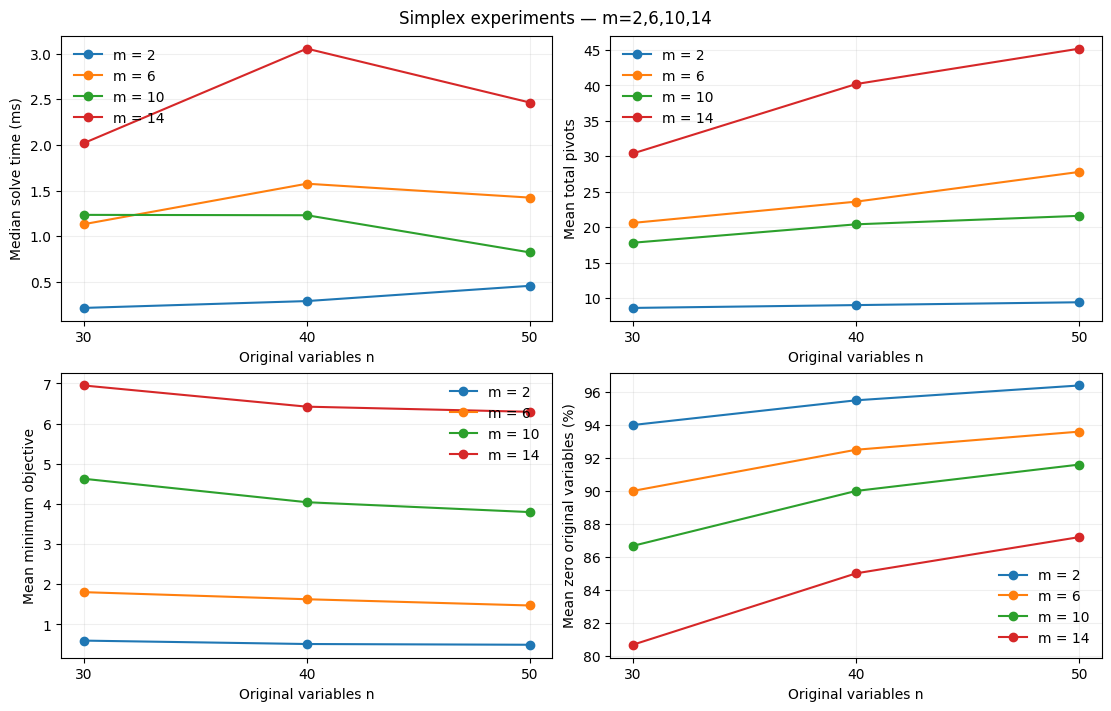

In [19]:
def plot_metric(axis, field_name, axis_label):
    # Each curve fixes the row count and varies the number of original variables.
    for constraint_count in CONSTRAINT_COUNTS:
        variable_counts = []
        metric_values = []
        for record in summary_results:
            if record['m'] == constraint_count:
                variable_counts.append(record['n'])
                metric_values.append(record[field_name])

        axis.plot(variable_counts, metric_values, marker='o', label=f'm = {constraint_count}')

    axis.set_xlabel('Original variables n')
    axis.set_ylabel(axis_label)
    axis.set_xticks(VARIABLE_COUNTS)
    axis.grid(alpha=0.2)
    axis.legend(frameon=False)


figure, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
plot_metric(axes[0, 0], 'median_ms', 'Median solve time (ms)')
plot_metric(axes[0, 1], 'mean_pivots', 'Mean total pivots')
plot_metric(axes[1, 0], 'mean_objective', 'Mean minimum objective')
plot_metric(axes[1, 1], 'mean_zero_percent', 'Mean zero original variables (%)')
figure.suptitle('Simplex experiments — m=2,6,10,14')
display(figure)
plt.close(figure)


### Check the objective trends


In [20]:
results_by_case = {}
for record in case_results:
    case_key = (record['seed'], record['n'], record['m'])
    results_by_case[case_key] = record

for seed in RANDOM_SEEDS:
    # Adding variables preserves older solutions, so minimum cost cannot increase.
    for constraint_count in CONSTRAINT_COUNTS:
        previous_objective = None
        for variable_count in VARIABLE_COUNTS:
            objective = results_by_case[seed, variable_count, constraint_count]['objective']
            if previous_objective is not None:
                assert objective <= previous_objective + 1e-7
            previous_objective = objective

    # Adding constraints restricts feasible solutions, so minimum cost cannot decrease.
    for variable_count in VARIABLE_COUNTS:
        previous_objective = None
        for constraint_count in CONSTRAINT_COUNTS:
            objective = results_by_case[seed, variable_count, constraint_count]['objective']
            if previous_objective is not None:
                assert objective >= previous_objective - 1e-7
            previous_objective = objective

print('All per-seed objective direction checks passed.')


All per-seed objective direction checks passed.


## 7 Special cases


In [21]:
def special_cases():
    return {
        'bounded_reference': {
            'c': [-1.0],
            'A_ub': [[1.0]],
            'b_ub': [1.0],
        },
        'unbounded_after_removal': {
            'c': [-1.0],
        },
        'infeasible': {
            'c': [1.0],
            'A_ub': [[1.0], [-1.0]],
            'b_ub': [1.0, -2.0],
        },
        'multiple_optima': {
            'c': [1.0, 1.0],
            'A_eq': [[1.0, 1.0]],
            'b_eq': [1.0],
        },
        'degenerate_vertex': {
            'c': [1.0, 2.0],
            'A_eq': [[1.0, 1.0]],
            'b_eq': [0.0],
        },
        'redundant_equalities': {
            'c': [1.0, 2.0],
            'A_eq': [[1.0, 1.0], [2.0, 2.0]],
            'b_eq': [1.0, 2.0],
        },
    }


In [22]:
special_results = []
for example_name, problem in special_cases().items():
    # These small models illustrate outcomes that the feasible, bounded grid cannot show.
    solution = simplex(**problem)
    verification = validate(problem, solution)
    result = {'name': example_name, 'problem': problem}
    result.update(solution)
    result.update(verification)
    special_results.append(result)

display_table(special_results, [
    ('name', 'Example'),
    ('status', 'Status'),
    ('objective', 'Minimum'),
    ('x', 'Solution x'),
    ('pivots', 'Pivots'),
    ('degenerate_pivots', 'Zero-step pivots'),
    ('removed_redundant_rows', 'Removed rows'),
])
print('None means that no finite optimal solution was returned.')


Example | Status | Minimum | Solution x | Pivots | Zero-step pivots | Removed rows
--- | --- | --- | --- | --- | --- | ---
bounded_reference | optimal | -1 | [1.0] | 1 | 0 | 0
unbounded_after_removal | unbounded | None | None | 0 | 0 | 0
infeasible | infeasible | None | None | 1 | 0 | 0
multiple_optima | optimal | 1 | [1.0, 0.0] | 1 | 0 | 0
degenerate_vertex | optimal | 0 | [0.0, 0.0] | 1 | 1 | 0
redundant_equalities | optimal | 1 | [1.0, 0.0] | 1 | 0 | 1

None means that no finite optimal solution was returned.


### Multiple optimal solutions


In [23]:
points = [[1, 0], [0, 1], [0.5, 0.5]]
objective_coefficients = np.array([1, 1])

# Each distinct point satisfies x1 + x2 = 1 and has the same minimum cost.
for point in points:
    variable_values = np.array(point, dtype=float)
    assert np.all(variable_values >= 0)
    assert np.isclose(variable_values.sum(), 1)
    objective_value = float(objective_coefficients @ variable_values)
    print('Feasible point:', point, '| cost:', objective_value)


Feasible point: [1, 0] | cost: 1.0
Feasible point: [0, 1] | cost: 1.0
Feasible point: [0.5, 0.5] | cost: 1.0
